# Cross-checking the SDE engine in Python

The Kotlin engine in `shared/` is tested by its own unit tests. This notebook redoes the same checks independently with numpy, so the numbers can be compared in a language that is quicker to poke at.

Each section states the closed form, simulates it, and prints the simulated value next to the exact one. Run it with `pip install -r requirements.txt`, then `jupyter lab`.

In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

rng = np.random.default_rng(2024)

def euler_maruyama(mu, sigma, x0, T, n, paths, rng):
    """Vectorised Euler–Maruyama for dX = mu(t, X) dt + sigma(t, X) dW. Returns X on the grid, shape (n + 1, paths)."""
    dt = T / n
    x = np.empty((n + 1, paths)); x[0] = x0
    for i in range(n):
        dW = np.sqrt(dt) * rng.standard_normal(paths)
        x[i + 1] = x[i] + mu(i * dt, x[i]) * dt + sigma(i * dt, x[i]) * dW
    return x

def report(label, simulated, exact, stderr=None):
    z = f"  ({(simulated - exact) / stderr:+.2f} standard errors)" if stderr else ""
    print(f"{label:<28} simulated {simulated:12.6f}   exact {exact:12.6f}{z}")

## Geometric Brownian motion

$dS = \mu S\,dt + \sigma S\,dW$ has $E[S_t] = S_0 e^{\mu t}$ and $\operatorname{Var}[S_t] = S_0^2 e^{2\mu t}(e^{\sigma^2 t} - 1)$.

E[S(1)]                      simulated   110.450661   exact   110.517092  (-0.62 standard errors)
Var[S(1)]                    simulated  1147.072066   exact  1150.247299


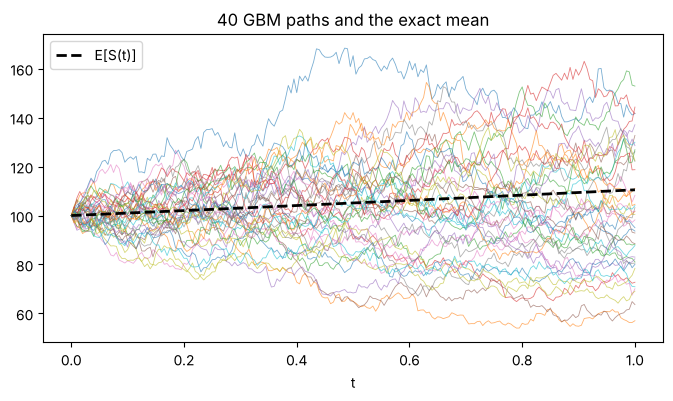

In [2]:
mu, sigma, S0, T = 0.1, 0.3, 100.0, 1.0
paths = 100_000
S = euler_maruyama(lambda t, x: mu * x, lambda t, x: sigma * x, S0, T, 200, paths, rng)
report("E[S(1)]", S[-1].mean(), S0 * np.exp(mu * T), S[-1].std(ddof=1) / np.sqrt(paths))
report("Var[S(1)]", S[-1].var(ddof=1), S0**2 * np.exp(2 * mu * T) * (np.exp(sigma**2 * T) - 1))

t = np.linspace(0, T, 201)
plt.figure(figsize=(8, 4))
plt.plot(t, S[:, :40], lw=0.6, alpha=0.6)
plt.plot(t, S0 * np.exp(mu * t), "k--", lw=2, label="E[S(t)]")
plt.title("40 GBM paths and the exact mean"); plt.xlabel("t"); plt.legend(); plt.show()

## Strong convergence orders

Using GBM's exact solution $S_T = S_0 \exp((\mu - \sigma^2/2)T + \sigma W_T)$ driven by the *same* Brownian path, the error $E|X_N - S_T|$ should fall like $\Delta t^{1/2}$ for Euler–Maruyama and $\Delta t^{1}$ for Milstein. The Kotlin `ConvergenceTest` measures the same slopes.

Euler–Maruyama  strong order ≈ 0.498
Milstein        strong order ≈ 0.938


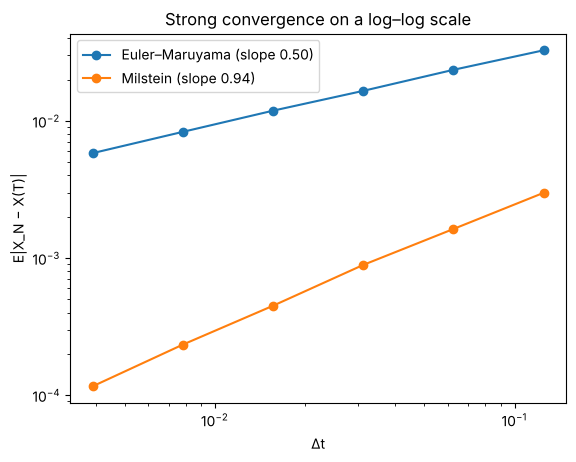

In [3]:
mu, sigma, x0, T = 0.06, 0.4, 1.0, 1.0
levels = np.array([8, 16, 32, 64, 128, 256]); finest = levels.max(); paths = 4000
dW = np.sqrt(T / finest) * rng.standard_normal((paths, finest))
exact = x0 * np.exp((mu - 0.5 * sigma**2) * T + sigma * dW.sum(axis=1))

def strong_error(milstein):
    errors = []
    for n in levels:
        dt = T / n
        inc = dW.reshape(paths, n, finest // n).sum(axis=2)
        x = np.full(paths, x0)
        for i in range(n):
            d = inc[:, i]
            x = x + mu * x * dt + sigma * x * d + (0.5 * sigma**2 * x * (d**2 - dt) if milstein else 0)
        errors.append(np.abs(x - exact).mean())
    return np.array(errors)

dts = T / levels
for name, milstein in [("Euler–Maruyama", False), ("Milstein", True)]:
    err = strong_error(milstein)
    order = np.polyfit(np.log(dts), np.log(err), 1)[0]
    print(f"{name:<15} strong order ≈ {order:.3f}")
    plt.loglog(dts, err, "o-", label=f"{name} (slope {order:.2f})")
plt.xlabel("Δt"); plt.ylabel("E|X_N − X(T)|"); plt.title("Strong convergence on a log–log scale"); plt.legend(); plt.show()

## Ornstein–Uhlenbeck and Cox–Ingersoll–Ross

OU: $E[X_t] = m + (x_0 - m)e^{-\kappa t}$, $\operatorname{Var}[X_t] = \frac{\sigma^2}{2\kappa}(1 - e^{-2\kappa t})$.
CIR has the same mean with $\theta$ for $m$; the Kotlin engine uses full truncation, $\max(X, 0)$ inside both coefficients.

In [4]:
kappa, m, sigma, x0, T = 2.0, 1.0, 0.5, -1.0, 2.0
X = euler_maruyama(lambda t, x: kappa * (m - x), lambda t, x: sigma, x0, T, 400, 100_000, rng)
report("OU E[X(2)]", X[-1].mean(), m + (x0 - m) * np.exp(-kappa * T))
report("OU Var[X(2)]", X[-1].var(ddof=1), sigma**2 / (2 * kappa) * (1 - np.exp(-2 * kappa * T)))

kappa, theta, sigma, r0 = 2.0, 0.04, 0.2, 0.03
R = euler_maruyama(lambda t, x: kappa * (theta - np.maximum(x, 0)),
                   lambda t, x: sigma * np.sqrt(np.maximum(x, 0)), r0, T, 400, 100_000, rng)
e = np.exp(-kappa * T)
report("CIR E[r(2)]", R[-1].mean(), theta + (r0 - theta) * e)
report("CIR Var[r(2)]", R[-1].var(ddof=1), r0 * sigma**2 / kappa * (e - e**2) + theta * sigma**2 / (2 * kappa) * (1 - e)**2)

OU E[X(2)]                   simulated     0.963299   exact     0.963369
OU Var[X(2)]                 simulated     0.062827   exact     0.062479


CIR E[r(2)]                  simulated     0.039762   exact     0.039817
CIR Var[r(2)]                simulated     0.000401   exact     0.000396


## European call: Monte Carlo against Black–Scholes

Under the risk-neutral measure $\mu = r$, and the price is $e^{-rT}E[(S_T - K)^+]$. Antithetic variates reuse each normal draw $Z$ as $-Z$, which shrinks the standard error at no extra cost.

In [5]:
S0, K, r, sigma, T, n = 100.0, 105.0, 0.05, 0.2, 1.0, 200_000
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T)); d2 = d1 - sigma * np.sqrt(T)
bs = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

Z = rng.standard_normal(n)
payoff = lambda z: np.exp(-r * T) * np.maximum(S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * z) - K, 0)
plain = payoff(Z)
anti = 0.5 * (payoff(Z[: n // 2]) + payoff(-Z[: n // 2]))
report("call, plain MC", plain.mean(), bs, plain.std(ddof=1) / np.sqrt(n))
report("call, antithetic", anti.mean(), bs, anti.std(ddof=1) / np.sqrt(n // 2))
print(f"standard error: plain {plain.std(ddof=1) / np.sqrt(n):.4f}, antithetic {anti.std(ddof=1) / np.sqrt(n // 2):.4f}")

call, plain MC               simulated     7.955016   exact     8.021352  (-2.26 standard errors)
call, antithetic             simulated     8.000579   exact     8.021352  (-0.89 standard errors)
standard error: plain 0.0294, antithetic 0.0234


## Itô versus Stratonovich: $\int_0^t W\,dW$

Evaluating the integrand at the left end point (Itô) gives $\tfrac12 W_t^2 - \tfrac12 t$; averaging the two end points (Stratonovich) gives $\tfrac12 W_t^2$, as ordinary calculus would. The gap is half the quadratic variation $\sum (\Delta W)^2 \to t$.

Itô sum at T                 simulated     0.546961   exact     0.546409
Stratonovich sum at T        simulated     1.046409   exact     1.046409
quadratic variation at T     simulated     0.998897   exact     1.000000


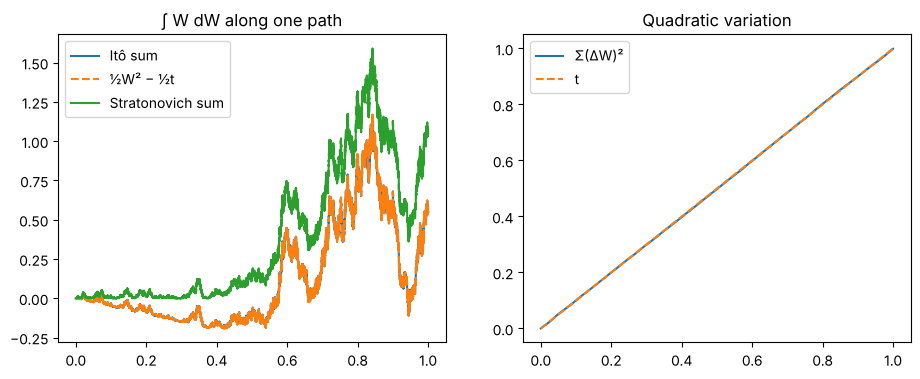

In [6]:
n, T = 100_000, 1.0
t = np.linspace(0, T, n + 1)
W = np.concatenate([[0], np.cumsum(np.sqrt(T / n) * rng.standard_normal(n))])
dW = np.diff(W)
ito = np.concatenate([[0], np.cumsum(W[:-1] * dW)])
strat = np.concatenate([[0], np.cumsum(0.5 * (W[:-1] + W[1:]) * dW)])
qv = np.concatenate([[0], np.cumsum(dW**2)])
report("Itô sum at T", ito[-1], 0.5 * W[-1]**2 - 0.5 * T)
report("Stratonovich sum at T", strat[-1], 0.5 * W[-1]**2)
report("quadratic variation at T", qv[-1], T)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t, ito, label="Itô sum"); ax[0].plot(t, 0.5 * W**2 - 0.5 * t, "--", label="½W² − ½t")
ax[0].plot(t, strat, label="Stratonovich sum"); ax[0].legend(); ax[0].set_title("∫ W dW along one path")
ax[1].plot(t, qv, label="Σ(ΔW)²"); ax[1].plot(t, t, "--", label="t"); ax[1].legend(); ax[1].set_title("Quadratic variation")
plt.show()

## Merton jump diffusion

With $k = e^{m + \delta^2/2} - 1$ the compensated drift gives $E[S_t] = S_0 e^{\mu t}$, and
$E[S_t^2] = S_0^2 \exp\big(2\mu t - 2\lambda k t + \sigma^2 t + \lambda t (e^{2m + 2\delta^2} - 1)\big)$.

In [7]:
S0, mu, sigma, lam, jm, jv, T, n, paths = 100.0, 0.05, 0.2, 3.0, -0.1, 0.15, 1.0, 50, 100_000
k = np.exp(jm + 0.5 * jv**2) - 1
dt = T / n
logS = np.full(paths, np.log(S0))
for _ in range(n):
    N = rng.poisson(lam * dt, paths)
    logS += (mu - lam * k - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * rng.standard_normal(paths) \
            + N * jm + np.sqrt(N) * jv * rng.standard_normal(paths)
S = np.exp(logS)
second = S0**2 * np.exp(2 * mu * T - 2 * lam * k * T + sigma**2 * T + lam * T * (np.exp(2 * jm + 2 * jv**2) - 1))
report("Merton E[S(1)]", S.mean(), S0 * np.exp(mu * T), S.std(ddof=1) / np.sqrt(paths))
report("Merton Var[S(1)]", S.var(ddof=1), second - (S0 * np.exp(mu * T))**2)

Merton E[S(1)]               simulated   105.278826   exact   105.127110  (+1.28 standard errors)
Merton Var[S(1)]             simulated  1395.863305   exact  1394.109830
